In [37]:
#########
## SET UP
#########

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# training data
X_train = pd.read_csv("projectA/projectA_train_expression.csv.gz")
y_train = pd.read_csv("projectA/projectA_train_metadata.csv")

# test data
X_test = pd.read_csv("projectA/projectA_test_expression.csv.gz")
test_metadata = pd.read_csv("projectA/projectA_test_metadata.csv")

# additional info
gene_annotation = pd.read_csv("projectA/projectA_gene_annotation.csv")
submission = pd.read_csv("projectA/projectA_submission_template.csv")


A1.1 Metadata table

In [113]:
#################
## METADATA TABLE
#################

# info
#print(y_train.head())
samples_per_woman = y_train['woman_id'].value_counts()
#print("Samples per woman:\n",samples_per_woman)

sample_mean = y_train['woman_id'].value_counts().mean()
print("Average sample size per woman:\n", round(sample_mean, 4))

samples_per_group = y_train.groupby(["group", "woman_id"]).size().groupby("group").mean()

samples_per_group = y_train.groupby(["group", "woman_id"]).size().groupby("group").value_counts()

print("Average sample size by group:\n", samples_per_group)

Average sample size per woman:
 4.7051
Average sample size by group:
 group                
Control             6    17
                    1     8
                    3     8
                    5     4
                    4     2
Early_Preeclampsia  6     3
                    5     1
                    4     1
                    7     1
PPROM               5     7
                    6     4
                    4     3
                    7     3
sPTD                6     4
                    7     3
                    4     3
                    5     3
                    2     2
                    3     1
Name: count, dtype: int64


In [33]:
####################
## EXPLORATORY STATS
####################
print("X_train:\n",X_train.shape)

print("y_train:\n",y_train.shape)

## NAs
print(X_train.isna().sum().sum())
print(y_train.isna().sum())
# no NAs in data

## check if every sample can be identified in X_train
print(set(X_train["sample_id"]) == set(y_train["sample_id"]))
# true

X_train:
 (367, 32831)
y_train:
 (367, 5)
0
sample_id          0
woman_id           0
batch              0
group              0
gestational_age    0
dtype: int64


<Figure size 640x480 with 0 Axes>

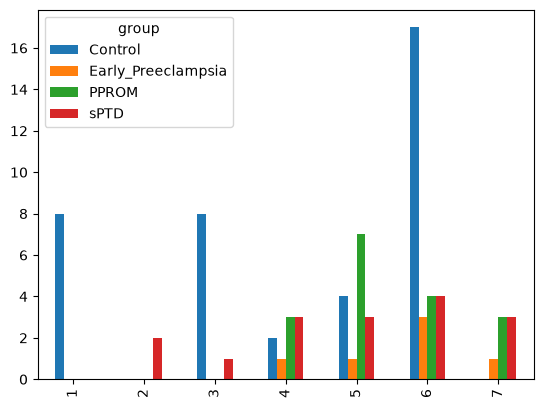

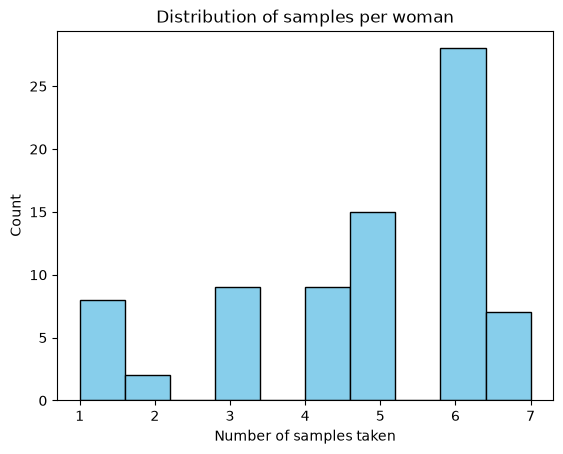

In [158]:
#################
## VISUALISATIONS
#################
## samples per group
x = np.arange(6)+1

#samples_per_group.plot(kind="bar")
plt.figure()
test = samples_per_group.unstack(level=0)
#print(test)
test.plot(kind='bar')
plt.show()


## samples per woman
plt.figure()
plt.hist(samples_per_woman, color="skyblue", edgecolor="black")
plt.xlabel("Number of samples taken")
plt.ylabel("Count")
plt.title("Distribution of samples per woman")
plt.show()

## ga range per group

#samples_per_group.plot(kind='bar')


In [34]:
################
## DATA OVERVIEW
################

## dimensions
print(X_train.shape)
print(y_train.shape)
#print(X_test.shape)
#print(test_metadata.shape)

## overview
#print(X_train.head()) ## GA values per sample + gene
#print(y_train.head()) ## woman ID + sample ID + info
#print(y_train.info())
#print(y_train.describe(include="all"))

(367, 32831)
(367, 5)
True


In [7]:
# Number of samples
print("Number of samples:", len(y_train))

# Number of unique women
print("Number of unique woman:", y_train["woman_id"].nunique())

# Number of samples per woman
print("Samples per woman", y_train["woman_id"].value_counts())

print("Samples:", y_train["woman_id"].value_counts().describe())
## 50%: 5

# Distribution of gestational age
print("Gestational age:", y_train["gestational_age"].describe())

# Distribution of groups
print("Groups:", y_train["group"].value_counts())

# Distribution of batches
print("batches:", y_train["batch"].value_counts())

# Number of samples per woman and group
samples_per_woman = (
    y_train.groupby(["group", "woman_id"])["sample_id"]
    .nunique()
    .reset_index(name="n_samples")
)

# Average samples per woman per group
print(samples_per_woman.groupby("group")["n_samples"].mean())

Number of samples: 367
Number of unique woman: 78
Samples per woman woman_id
W047    7
W082    7
W049    7
W064    7
W107    7
       ..
W138    1
W073    1
W076    1
W096    1
W023    1
Name: count, Length: 78, dtype: int64
Samples: count    78.000000
mean      4.705128
std       1.766271
min       1.000000
25%       4.000000
50%       5.000000
75%       6.000000
max       7.000000
Name: count, dtype: float64
Gestational age: count    367.000000
mean      26.060218
std        8.390041
min        9.100000
25%       19.400000
50%       26.400000
75%       33.200000
max       40.300000
Name: gestational_age, dtype: float64
Groups: group
Control               162
PPROM                  92
sPTD                   79
Early_Preeclampsia     34
Name: count, dtype: int64
batches: batch
4     49
7     48
2     38
10    38
6     37
1     33
32    32
3     32
8     28
9     25
5      7
Name: count, dtype: int64
group
Control               4.153846
Early_Preeclampsia    5.666667
PPROM              